In [ ]:
import numpy as np
import pandas as pd

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/melanoma/test/Benign/6588.jpg
/kaggle/input/melanoma/test/Benign/6399.jpg
/kaggle/input/melanoma/test/Benign/6324.jpg
/kaggle/input/melanoma/test/Benign/7222.jpg
/kaggle/input/melanoma/test/Benign/6560.jpg
/kaggle/input/melanoma/test/Benign/6943.jpg
/kaggle/input/melanoma/test/Benign/6365.jpg
/kaggle/input/melanoma/test/Benign/6459.jpg
/kaggle/input/melanoma/test/Benign/6653.jpg
/kaggle/input/melanoma/test/Benign/7006.jpg
/kaggle/input/melanoma/test/Benign/6925.jpg
/kaggle/input/melanoma/test/Benign/7245.jpg
/kaggle/input/melanoma/test/Benign/6800.jpg
/kaggle/input/melanoma/test/Benign/6899.jpg
/kaggle/input/melanoma/test/Benign/6831.jpg
/kaggle/input/melanoma/test/Benign/7061.jpg
/kaggle/input/melanoma/test/Benign/6337.jpg
/kaggle/input/melanoma/test/Benign/6513.jpg
/kaggle/input/melanoma/test/Benign/6493.jpg
/kaggle/input/melanoma/test/Benign/6797.jpg
/kaggle/input/melanoma/test/Benign/6794.jpg
/kaggle/input/melanoma/test/Benign/6367.jpg
/kaggle/input/melanoma/test/Beni

In [ ]:
# @title 1. Setup and Configuration
import os
import time
import copy
import math

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import transforms, datasets, models
from torch.utils.data import DataLoader, Dataset
from PIL import Image

import numpy as np
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

BATCH_SIZE = 256
EPOCHS_PRETRAIN = 100
EPOCHS_LINEAR_EVAL = 100
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-6
PROJECTION_DIM = 256
HIDDEN_DIM = 4096
MOMENTUM_BASE = 0.99
NUM_WORKERS = 2

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)



Using device: cuda


In [ ]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder("/kaggle/input/melanoma/train", transform=transform)
test_dataset  = datasets.ImageFolder("/kaggle/input/melanoma/test", transform=transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
test_loader  = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

num_classes = len(train_dataset.classes)
print("Classes:", train_dataset.classes)
print("Train size:", len(train_dataset), "Test size:", len(test_dataset))



Classes: ['Benign', 'Malignant']
Train size: 11879 Test size: 2000


In [ ]:
SAVE_DIR = "/kaggle/working/cse475-project-outputs"
os.makedirs(SAVE_DIR, exist_ok=True)

print("Saving to:", SAVE_DIR)


Saving to: /kaggle/working/cse475-project-outputs


In [ ]:
# @title 2. BYOL Data Augmentations

class CustomBYOLTransform:
    def __init__(self, size=32):
        normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                         std=[0.229, 0.224, 0.225])

        self.transform1 = transforms.Compose([
            transforms.RandomResizedCrop(size=size, scale=(0.2, 1.0)),
            transforms.RandomHorizontalFlip(),
            transforms.RandomApply([
                transforms.ColorJitter(0.8, 0.8, 0.8, 0.2)
            ], p=0.8),
            transforms.RandomGrayscale(p=0.2),
            transforms.RandomApply([transforms.GaussianBlur(kernel_size=int(0.1 * size))], p=0.5), # Crucial for BYOL
            transforms.ToTensor(),
            normalize
        ])

        self.transform2 = transforms.Compose([
            transforms.RandomResizedCrop(size=size, scale=(0.2, 1.0)),
            transforms.RandomHorizontalFlip(),
            transforms.RandomApply([
                transforms.ColorJitter(0.8, 0.8, 0.8, 0.2)
            ], p=0.8),
            transforms.RandomGrayscale(p=0.2),
            transforms.RandomApply([transforms.GaussianBlur(kernel_size=int(0.1 * size))], p=0.5), # Crucial for BYOL
            transforms.ToTensor(),
            normalize
        ])

    def __call__(self, x):
        return self.transform1(x), self.transform2(x)

class CIFAR10BYOL(datasets.CIFAR10):
    def __init__(self, root, train=True, transform=None, download=False):
        super().__init__(root, train=train, transform=transform, download=download)

    def __getitem__(self, index):
        img, target = self.data[index], self.targets[index]
        img = Image.fromarray(img)

        if self.transform is not None:

            return self.transform(img)
        else:
            return img, target

train_dataset_byol = CIFAR10BYOL(root='./data', train=True, download=True, transform=CustomBYOLTransform())
train_loader_byol = DataLoader(train_dataset_byol, batch_size=BATCH_SIZE, shuffle=True,
                               num_workers=NUM_WORKERS, drop_last=True, pin_memory=True)

train_transform_eval = transforms.Compose([
    transforms.RandomResizedCrop(32),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
test_transform_eval = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset_eval = datasets.CIFAR10(root='./data', train=True, download=True, transform=train_transform_eval)
test_dataset_eval = datasets.CIFAR10(root='./data', train=False, download=True, transform=test_transform_eval)

train_loader_eval = DataLoader(train_dataset_eval, batch_size=BATCH_SIZE, shuffle=True,
                               num_workers=NUM_WORKERS, pin_memory=True)
test_loader_eval = DataLoader(test_dataset_eval, batch_size=BATCH_SIZE, shuffle=False,
                              num_workers=NUM_WORKERS, pin_memory=True)

print(f"BYOL training dataset size: {len(train_dataset_byol)}")
print(f"Linear evaluation training dataset size: {len(train_dataset_eval)}")
print(f"Linear evaluation test dataset size: {len(test_dataset_eval)}")

100%|██████████| 170M/170M [00:03<00:00, 50.9MB/s] 


BYOL training dataset size: 50000
Linear evaluation training dataset size: 50000
Linear evaluation test dataset size: 10000


In [ ]:
import torch
import torch.nn as nn
import torchvision.models as models
import copy

class BYOLResNet(nn.Module):
    def __init__(self):
        super().__init__()

        densenet201 = models.densenet201(weights=None)

        self.encoder = nn.Sequential(*list(densenet201.children())[:-1])

        self.feature_dim = 1920

    def forward(self, x):
        return self.encoder(x).view(x.size(0), -1)

class ProjectionHead(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, output_dim)
        )

    def forward(self, x):
        return self.net(x)


class PredictionHead(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, output_dim)
        )

    def forward(self, x):
        return self.net(x)

class BYOL(nn.Module):
    def __init__(self, encoder: BYOLResNet, projection_dim, hidden_dim):
        super().__init__()
        self.online_encoder = encoder
        self.online_projector = ProjectionHead(encoder.feature_dim, hidden_dim, projection_dim)
        self.online_predictor = PredictionHead(projection_dim, hidden_dim, projection_dim)

        self.target_encoder = copy.deepcopy(encoder)
        self.target_projector = copy.deepcopy(self.online_projector)


        for param in self.target_encoder.parameters():
            param.requires_grad = False
        for param in self.target_projector.parameters():
            param.requires_grad = False

    def forward(self, x1, x2):

        online_proj_out1 = self.online_projector(self.online_encoder(x1))
        online_pred_out1 = self.online_predictor(online_proj_out1)

        online_proj_out2 = self.online_projector(self.online_encoder(x2))
        online_pred_out2 = self.online_predictor(online_proj_out2)


        with torch.no_grad():
            target_proj_out1 = self.target_projector(self.target_encoder(x1))
            target_proj_out2 = self.target_projector(self.target_encoder(x2))

        return online_pred_out1, online_pred_out2, target_proj_out1, target_proj_out2


    def update_target_network(self, momentum):
        for online_param, target_param in zip(self.online_encoder.parameters(), self.target_encoder.parameters()):
            target_param.data = target_param.data * momentum + online_param.data * (1. - momentum)
        for online_param, target_param in zip(self.online_projector.parameters(), self.target_projector.parameters()):
            target_param.data = target_param.data * momentum + online_param.data * (1. - momentum)

byol_encoder = BYOLResNet().to(DEVICE)
byol_model = BYOL(byol_encoder, PROJECTION_DIM, HIDDEN_DIM).to(DEVICE)

print(byol_model)


BYOL(
  (online_encoder): BYOLResNet(
    (encoder): Sequential(
      (0): Sequential(
        (conv0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
        (norm0): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu0): ReLU(inplace=True)
        (pool0): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
        (denseblock1): _DenseBlock(
          (denselayer1): _DenseLayer(
            (norm1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (relu1): ReLU(inplace=True)
            (conv1): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
            (norm2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (relu2): ReLU(inplace=True)
            (conv2): Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          )
          (denselayer2): _DenseLayer(
  

In [ ]:
# @title 4. BYOL Loss Function
def byol_loss(online_pred, target_proj):

   online_pred_norm = F.normalize(online_pred, dim=-1)
    target_proj_norm = F.normalize(target_proj, dim=-1)

    loss = 2 - 2 * (online_pred_norm * target_proj_norm).sum(dim=-1)
    return loss.mean()

In [ ]:
import math, time, os
import torch
import torch.optim as optim


EPOCHS_PRETRAIN = 100
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
MOMENTUM_BASE = 0.996
SAVE_DIR = "./checkpoints"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

os.makedirs(SAVE_DIR, exist_ok=True)

def adjust_learning_rate(optimizer, init_lr, epoch, total_epochs):
    lr = init_lr * 0.5 * (1. + math.cos(math.pi * epoch / total_epochs))
    for param_group in optimizer.param_groups:
        param_group['lr'] = lr

def adjust_momentum(epoch, total_epochs, momentum_base):
    return 1. - (1. - momentum_base) * (math.cos(math.pi * epoch / total_epochs) + 1) / 2

print("--- Starting BYOL Self-Supervised Pre-training ---")
optimizer = optim.AdamW(byol_model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
pretrain_losses = []

for epoch in range(1, EPOCHS_PRETRAIN + 1):
    byol_model.train()
    total_loss, start_time = 0.0, time.time()

    adjust_learning_rate(optimizer, LEARNING_RATE, epoch, EPOCHS_PRETRAIN)
    momentum = adjust_momentum(epoch, EPOCHS_PRETRAIN, MOMENTUM_BASE)

    for x1, x2 in train_loader_byol:
        x1, x2 = x1.to(DEVICE), x2.to(DEVICE)

        optimizer.zero_grad()
        out1, out2, tgt1, tgt2 = byol_model(x1, x2)

        loss = byol_loss(out1, tgt2) + byol_loss(out2, tgt1)
        loss.backward()
        optimizer.step()

        with torch.no_grad():
            byol_model.update_target_network(momentum)

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader_byol)
    pretrain_losses.append(avg_loss)
    elapsed = time.time() - start_time
    print(f"Epoch {epoch:03}/{EPOCHS_PRETRAIN} | Loss: {avg_loss:.4f} | "
          f"LR: {optimizer.param_groups[0]['lr']:.6f} | "
          f"Momentum: {momentum:.4f} | Time: {elapsed:.1f}s")

    if epoch % 20 == 0:
        checkpoint_path = os.path.join(SAVE_DIR, f"byol_epoch_{epoch}.pth")
        torch.save(byol_model.state_dict(), checkpoint_path)
        print(f"Checkpoint saved at epoch {epoch}: {checkpoint_path}")

print("--- BYOL Pre-training Finished ---")
save_path = os.path.join(SAVE_DIR, "byol_encoder_cifar10.pth")
torch.save(byol_model.online_encoder.state_dict(), save_path)
print(f"Saved encoder to {save_path}")


--- Starting BYOL Self-Supervised Pre-training ---
Epoch 001/100 | Loss: 2.0514 | LR: 0.000300 | Momentum: 0.9960 | Time: 107.8s
Epoch 002/100 | Loss: 1.7447 | LR: 0.000300 | Momentum: 0.9960 | Time: 111.6s
Epoch 003/100 | Loss: 1.4465 | LR: 0.000299 | Momentum: 0.9960 | Time: 108.1s
Epoch 004/100 | Loss: 1.2451 | LR: 0.000299 | Momentum: 0.9960 | Time: 106.3s
Epoch 005/100 | Loss: 1.1212 | LR: 0.000298 | Momentum: 0.9960 | Time: 108.4s
Epoch 006/100 | Loss: 1.0223 | LR: 0.000297 | Momentum: 0.9960 | Time: 105.1s
Epoch 007/100 | Loss: 0.9635 | LR: 0.000296 | Momentum: 0.9960 | Time: 105.4s
Epoch 008/100 | Loss: 0.9149 | LR: 0.000295 | Momentum: 0.9961 | Time: 107.4s
Epoch 009/100 | Loss: 0.8936 | LR: 0.000294 | Momentum: 0.9961 | Time: 109.0s
Epoch 010/100 | Loss: 0.8579 | LR: 0.000293 | Momentum: 0.9961 | Time: 106.4s
Epoch 011/100 | Loss: 0.8356 | LR: 0.000291 | Momentum: 0.9961 | Time: 106.5s
Epoch 012/100 | Loss: 0.8163 | LR: 0.000289 | Momentum: 0.9961 | Time: 106.8s
Epoch 013/100

In [ ]:
# @title 6. Linear Evaluation (Downstream Task)
class LinearClassifier(nn.Module):
    def __init__(self, feature_dim, num_classes=10):
        super().__init__()
        self.fc = nn.Linear(feature_dim, num_classes)

    def forward(self, x):
        return self.fc(x)

print("\n--- Starting Linear Evaluation ---")


pretrained_encoder = BYOLResNet().to(DEVICE)
pretrained_encoder.load_state_dict(torch.load(os.path.join(SAVE_DIR, "byol_encoder_cifar10.pth")))

for param in pretrained_encoder.parameters():
    param.requires_grad = False


classifier = LinearClassifier(pretrained_encoder.feature_dim, num_classes=10).to(DEVICE)

optimizer_eval = optim.Adam(classifier.parameters(), lr=LEARNING_RATE)
criterion_eval = nn.CrossEntropyLoss()

linear_eval_train_losses = []
linear_eval_test_accuracies = []

for epoch in range(1, EPOCHS_LINEAR_EVAL + 1):
    classifier.train()
    total_loss = 0.0
    start_time = time.time()

    for images, labels in train_loader_eval:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer_eval.zero_grad()

        with torch.no_grad():
            features = pretrained_encoder(images)

        outputs = classifier(features)
        loss = criterion_eval(outputs, labels)

        loss.backward()
        optimizer_eval.step()
        total_loss += loss.item()

    avg_train_loss = total_loss / len(train_loader_eval)
    linear_eval_train_losses.append(avg_train_loss)


    classifier.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in test_loader_eval:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            features = pretrained_encoder(images)
            outputs = classifier(features)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    linear_eval_test_accuracies.append(accuracy)

    elapsed_time = time.time() - start_time
    print(f"Linear Eval Epoch {epoch}/{EPOCHS_LINEAR_EVAL} | Train Loss: {avg_train_loss:.4f} | Test Acc: {accuracy:.2f}% | Time: {elapsed_time:.1f}s")

print("--- Linear Evaluation Finished ---")


print("\n--- Training Baseline (Randomly Initialized Encoder) ---")
random_encoder = BYOLResNet().to(DEVICE)
random_classifier = LinearClassifier(random_encoder.feature_dim, num_classes=10).to(DEVICE)
random_model = nn.Sequential(random_encoder, random_classifier).to(DEVICE)

optimizer_random = optim.Adam(random_model.parameters(), lr=LEARNING_RATE)
criterion_random = nn.CrossEntropyLoss()

random_eval_test_accuracies = []

for epoch in range(1, EPOCHS_LINEAR_EVAL + 1):
    random_model.train()
    for images, labels in train_loader_eval:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer_random.zero_grad()
        outputs = random_model(images)
        loss = criterion_random(outputs, labels)
        loss.backward()
        optimizer_random.step()

    random_model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in test_loader_eval:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = random_model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    random_eval_test_accuracies.append(accuracy)

    if epoch % 10 == 0 or epoch == EPOCHS_LINEAR_EVAL:
        print(f"Random Baseline Eval Epoch {epoch}/{EPOCHS_LINEAR_EVAL} | Test Acc: {accuracy:.2f}%")

print("--- Random Baseline Training Finished ---")


--- Starting Linear Evaluation ---
Linear Eval Epoch 1/100 | Train Loss: 1.6679 | Test Acc: 43.91% | Time: 17.0s
Linear Eval Epoch 2/100 | Train Loss: 1.5838 | Test Acc: 44.90% | Time: 16.2s
Linear Eval Epoch 3/100 | Train Loss: 1.5526 | Test Acc: 46.42% | Time: 16.5s
Linear Eval Epoch 4/100 | Train Loss: 1.5340 | Test Acc: 48.13% | Time: 16.4s
Linear Eval Epoch 5/100 | Train Loss: 1.5177 | Test Acc: 46.92% | Time: 16.4s
Linear Eval Epoch 6/100 | Train Loss: 1.5137 | Test Acc: 48.77% | Time: 16.6s
Linear Eval Epoch 7/100 | Train Loss: 1.5020 | Test Acc: 46.91% | Time: 16.1s
Linear Eval Epoch 8/100 | Train Loss: 1.4965 | Test Acc: 48.37% | Time: 16.5s
Linear Eval Epoch 9/100 | Train Loss: 1.4859 | Test Acc: 48.35% | Time: 16.6s
Linear Eval Epoch 10/100 | Train Loss: 1.4868 | Test Acc: 48.87% | Time: 16.2s
Linear Eval Epoch 11/100 | Train Loss: 1.4803 | Test Acc: 48.58% | Time: 16.3s
Linear Eval Epoch 12/100 | Train Loss: 1.4781 | Test Acc: 48.67% | Time: 16.2s
Linear Eval Epoch 13/100 

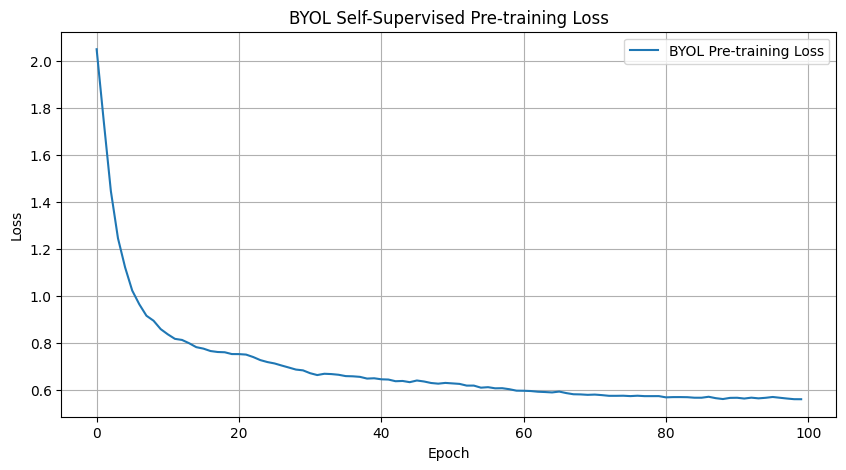

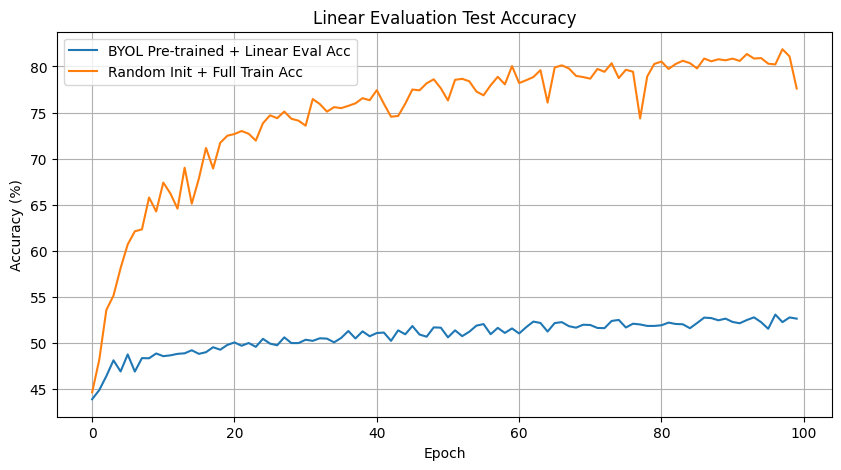


--- Visualizing Embedding Space with t-SNE ---
Running t-SNE on 1000 embeddings...


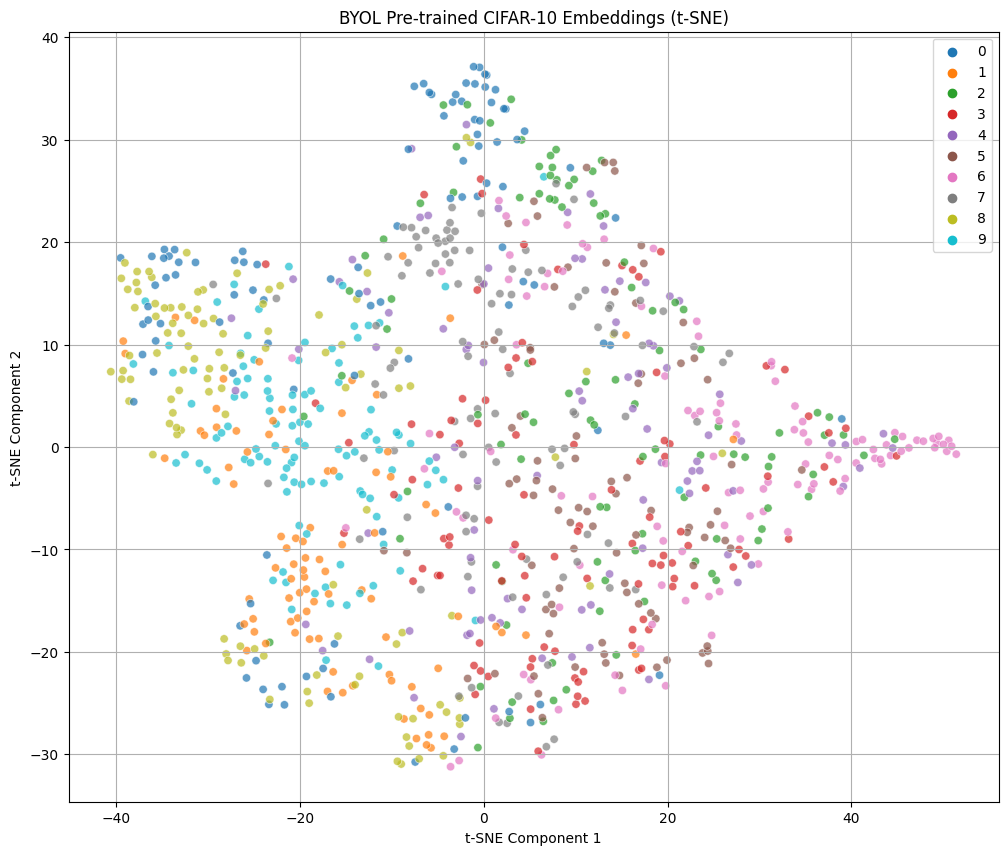

In [ ]:
# @title 7. Visualization of Impact
plt.figure(figsize=(10, 5))
plt.plot(pretrain_losses, label='BYOL Pre-training Loss')
plt.title('BYOL Self-Supervised Pre-training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()
plt.savefig(os.path.join(SAVE_DIR, "byol_pretrain_loss.png"))
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(linear_eval_test_accuracies, label='BYOL Pre-trained + Linear Eval Acc')
plt.plot(random_eval_test_accuracies, label='Random Init + Full Train Acc')
plt.title('Linear Evaluation Test Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.grid(True)
plt.legend()
plt.savefig(os.path.join(SAVE_DIR, "linear_eval_accuracy.png"))
plt.show()


print("\n--- Visualizing Embedding Space with t-SNE ---")

num_samples_tsne = 1000
subset_dataset_eval = torch.utils.data.Subset(test_dataset_eval, range(num_samples_tsne))
subset_loader_eval = DataLoader(subset_dataset_eval, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

pretrained_encoder.eval()
embeddings = []
labels = []

with torch.no_grad():
    for images, targets in subset_loader_eval:
        images = images.to(DEVICE)
        features = pretrained_encoder(images)
        embeddings.append(features.cpu().numpy())
        labels.append(targets.cpu().numpy())

embeddings = np.vstack(embeddings)
labels = np.concatenate(labels)

print(f"Running t-SNE on {embeddings.shape[0]} embeddings...")
tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000)
embeddings_2d = tsne.fit_transform(embeddings)

plt.figure(figsize=(12, 10))
sns.scatterplot(
    x=embeddings_2d[:, 0], y=embeddings_2d[:, 1],
    hue=labels, palette=sns.color_palette("tab10", 10),
    legend='full', alpha=0.7
)
plt.title('BYOL Pre-trained CIFAR-10 Embeddings (t-SNE)')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.grid(True)
plt.savefig(os.path.join(SAVE_DIR, "byol_embeddings_tsne.png"))
plt.show()



In [ ]:
import torch
import torch.nn as nn

# Define device (CPU or GPU if available)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Freeze BYOL encoder
encoder = byol_model.online_encoder
encoder.eval()
for param in encoder.parameters():
    param.requires_grad = False   # no gradient for encoder

# Suppose encoder outputs 2048-dim features
num_features = 2048
num_classes = 10  # CIFAR-10 for example

# Define linear classifier
classifier = nn.Linear(num_features, num_classes).to(device)

# Wrap encoder + classifier
model = nn.Sequential(
    encoder,
    classifier
).to(device)
